##### Part 2: Fine-tuning YOLO26s on VisDrone

## Goal

Adapt a pretrained YOLO26s detector to aerial imagery using the VisDrone2019-DET dataset.

We will:
1. Check the GPU and project paths.
2. Download/prepare VisDrone through Ultralytics.
3. Run a one-epoch smoke test to check that training works.
4. Fine-tune YOLO26s using the pretrained weights.
5. Validate the trained model on VisDrone.
6. Compare the original and fine-tuned models on the same AeroTrack drone-video frame.

**Important:** This notebook improves person detection. It does not solve tracking IDs or global person re-identification yet.

## Why VisDrone?

VisDrone contains drone-captured images with small objects and aerial viewpoints. Its 10 classes include:
- `pedestrian` — class 0
- `people` — class 1
- Other classes such as bicycles, cars, vans and buses

We keep the original VisDrone labels during training. During AeroTrack inference, we will filter to both person-related classes (0 and 1).

## Hardware note

This notebook is configured conservatively for a laptop GPU:
- YOLO26s pretrained weights
- image size 640
- batch size 1
- data-loader workers 0 (safer in Windows notebooks)
- mixed precision enabled when supported

Training may take a while. VisDrone is a multi-gigabyte download. Make sure you have a stable internet connection and several GB of free disk space.

##### Imports and project paths
If your video has another name, update `VIDEO_FILENAME`.

In [ ]:
from pathlib import Path
import time
import json
import cv2
import torch
import ultralytics
import matplotlib.pyplot as plt
import pandas as pd

from ultralytics import YOLO
from IPython.display import display, Image as IPyImage

# Project folders
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
RUNS_DIR = PROJECT_DIR / "runs"

DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)
RUNS_DIR.mkdir(exist_ok=True)

# Update this if your video filename is different.
VIDEO_FILENAME = "drone_video.mov"
VIDEO_PATH = DATA_DIR / VIDEO_FILENAME

print("Project:", PROJECT_DIR)
print("Ultralytics version:", ultralytics.__version__)
print("Video exists:", VIDEO_PATH.exists())

Project: c:\Users\anyan\source\repos\AeroTrack
Ultralytics version: 8.4.218
Video exists: True


## 2. Check GPU availability

The code uses CUDA device 0 when PyTorch can access the NVIDIA GPU. Otherwise it uses CPU.

We will not change your PyTorch installation in this notebook.

In [2]:
if torch.cuda.is_available():
    DEVICE = 0
    print("GPU:", torch.cuda.get_device_name(0))
    print("PyTorch CUDA:", torch.version.cuda)
    print("GPU memory (GB):", round(
        torch.cuda.get_device_properties(0).total_memory / (1024**3), 2
    ))
else:
    DEVICE = "cpu"
    print("CUDA is not available. Training on CPU will be very slow.")

print("Selected device:", DEVICE)

GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU
PyTorch CUDA: 13.2
GPU memory (GB): 4.0
Selected device: 0


## 3. Load the pretrained YOLO26s model

We start from `yolo26s.pt`, not a randomly initialized model. The model already has general visual features; fine-tuning adapts those features to aerial imagery.

The weights download automatically if they are not already available.

In [3]:
BASE_MODEL = "yolo26s.pt"

# Load pretrained weights.
base_model = YOLO(BASE_MODEL)

print("Model loaded:", BASE_MODEL)
print("Pretrained class count:", len(base_model.names))

Model loaded: yolo26s.pt
Pretrained class count: 80


## 4. Run a one-epoch training smoke test

This first run checks that:
- VisDrone can be downloaded and prepared.
- The labels can be read.
- The GPU can train the model with the selected batch size.

Ultralytics automatically downloads the VisDrone detection dataset when `data="VisDrone.yaml"` is used for the first time.

This smoke test is not the final training run. It trains for only one epoch.

In [ ]:
smoke_model = YOLO(BASE_MODEL)

smoke_start = time.time()

smoke_results = smoke_model.train(
    data="VisDrone.yaml",
    epochs=1,                   # Only one epoch for the setup check
    imgsz=640,
    batch=1,
    workers=0,
    device=DEVICE,
    amp=True,
    cache=False,
    plots=False,
    project=str(RUNS_DIR),
    name="visdrone_smoke_test",
    exist_ok=True,
    verbose=True
)

print("Smoke test completed in", round(time.time() - smoke_start, 1), "seconds")
print("Training setup appears to be working.")

Ultralytics 8.4.218  Python-3.14.7 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 3050 Ti Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=VisDrone.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=visdrone_smoke_test, nbs=64, nms=None, opset=None, 

###### Fine-tune YOLO26s on VisDrone

The training output, plots and model weights will be saved under `AeroTrack/runs/visdrone_yolo26s/`.

If you get a CUDA out-of-memory error, do not repeatedly rerun the same settings. Follow the fallback instructions near the end of this notebook.

In [5]:
trained_model = YOLO(BASE_MODEL)

training_start = time.time()

training_results = trained_model.train(
    data="VisDrone.yaml",
    epochs=50,
    imgsz=640,
    batch=1,
    workers=0,
    device=DEVICE,
    patience=15,
    amp=True,
    cache=False,
    save=True,
    plots=True,
    close_mosaic=10,
    project=str(RUNS_DIR),
    name="visdrone_yolo26s",
    exist_ok=True,
    verbose=True
)

training_seconds = time.time() - training_start

# Get the directory used by Ultralytics for this training run.
TRAIN_RUN_DIR = Path(trained_model.trainer.save_dir)
BEST_MODEL_PATH = TRAIN_RUN_DIR / "weights" / "best.pt"
LAST_MODEL_PATH = TRAIN_RUN_DIR / "weights" / "last.pt"

print("Training time (minutes):", round(training_seconds / 60, 1))
print("Training run folder:", TRAIN_RUN_DIR)
print("Best model exists:", BEST_MODEL_PATH.exists())
print("Best model path:", BEST_MODEL_PATH)

Ultralytics 8.4.218  Python-3.14.7 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 3050 Ti Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=VisDrone.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=visdrone_yolo26s, nbs=64, nms=None, opset=None, op

#### Load the best checkpoint and inspect its classes

Use `best.pt`, not `last.pt`, for evaluation. The best checkpoint is selected using validation performance during training.

VisDrone's two person-related categories are `pedestrian` and `people`. We will detect both in AeroTrack.

In [6]:
if not BEST_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Best checkpoint not found: {BEST_MODEL_PATH}. "
        "Check whether training completed successfully."
    )

best_model = YOLO(str(BEST_MODEL_PATH))

print("Fine-tuned model:", BEST_MODEL_PATH)
print("Class names:")

for class_id, class_name in best_model.names.items():
    print(class_id, ":", class_name)

PERSON_CLASS_IDS = [
    class_id
    for class_id, class_name in best_model.names.items()
    if class_name.lower() in {"pedestrian", "people"}
]

print("Person-related class IDs:", PERSON_CLASS_IDS)

if not PERSON_CLASS_IDS:
    raise ValueError("Could not find pedestrian/people classes in the model.")

Fine-tuned model: C:\Users\anyan\source\repos\AeroTrack\runs\visdrone_yolo26s\weights\best.pt
Class names:
0 : pedestrian
1 : people
2 : bicycle
3 : car
4 : van
5 : truck
6 : tricycle
7 : awning-tricycle
8 : bus
9 : motor
Person-related class IDs: [0, 1]


##### Validate the fine-tuned model on VisDrone

- Precision: how many predicted objects are correct.
- Recall: how many annotated objects the model finds.
- mAP50: detection quality at IoU 0.50.
- mAP50-95: stricter detection quality averaged across IoU thresholds.

In [7]:
validation_metrics = best_model.val(
    data="VisDrone.yaml",
    imgsz=640,
    batch=1,
    device=DEVICE,
    plots=True,
    project=str(RUNS_DIR),
    name="visdrone_validation",
    exist_ok=True
)

print("Validation completed.")
print("Results:", validation_metrics.results_dict)

Ultralytics 8.4.218  Python-3.14.7 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 3050 Ti Laptop GPU, 4096MiB)
YOLO26s summary (fused): 120 layers, 9,469,050 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access  (ping: 0.1±0.1 ms, read: 468.7±203.4 MB/s, size: 111.6 KB)
val: Scanning C:\Users\anyan\Desktop\life\school\computational intelligence\assignment\Lab 2\detection\datasets\VisDrone\labels\val.cache... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548 153.2Mit/s 0.0s
WARNING Dataset images contain up to 317 objects (val=317), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=317 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 548/548 8.4it/s 1:05<0.1sss2
                   all        548      38759      0.487     

#### Compare the original and fine-tuned models on AeroTrack footage

This is the practical comparison for our project.

We use the same frame, image size, confidence threshold and tiled inference for both models.

- Original YOLO26s uses COCO class 0 for `person`.
- Fine-tuned YOLO26s uses VisDrone's `pedestrian` and `people` classes.

The comparison is visual and uses the same test frame. It is not a formal accuracy score because this frame has not yet been manually annotated with ground-truth boxes.

Original YOLO26s detections: 7
Fine-tuned YOLO26s detections: 6


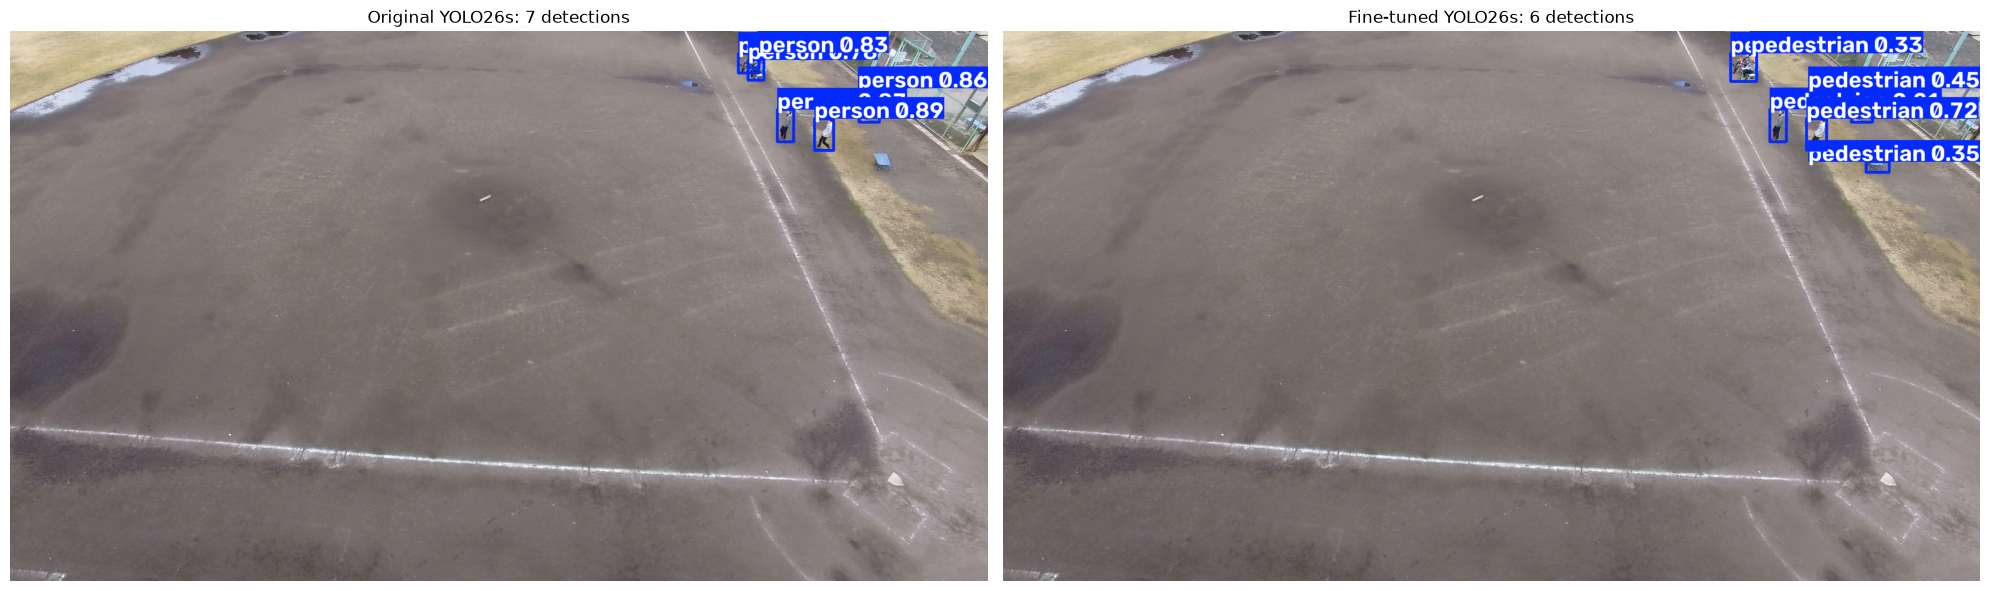

True

In [8]:
if not VIDEO_PATH.exists():
    raise FileNotFoundError(
        f"Video not found: {VIDEO_PATH}. Update VIDEO_FILENAME in Section 1."
    )

# Read the same approximate frame used in earlier AeroTrack experiments.
TEST_SECONDS = 65

cap = cv2.VideoCapture(str(VIDEO_PATH))
cap.set(cv2.CAP_PROP_POS_MSEC, TEST_SECONDS * 1000)

success, test_frame = cap.read()
cap.release()

if not success:
    raise ValueError("Could not read the selected test frame.")

# Original COCO-pretrained model.
original_model = YOLO(BASE_MODEL)

# Same inference settings for both models.
common_settings = {
    "source": test_frame,
    "imgsz": 640,
    "conf": 0.15,
    "max_det": 300,
    "device": DEVICE,
    "tile": 640,
    "tile_overlap": 0.20,
    "verbose": False
}

# Original model: COCO person class.
original_result = original_model.predict(
    classes=[0],
    **common_settings
)[0]

# Fine-tuned model: VisDrone pedestrian and people classes.
finetuned_result = best_model.predict(
    classes=PERSON_CLASS_IDS,
    **common_settings
)[0]

original_count = len(original_result.boxes)
finetuned_count = len(finetuned_result.boxes)

print("Original YOLO26s detections:", original_count)
print("Fine-tuned YOLO26s detections:", finetuned_count)

# Plot both results side by side.
fig, axes = plt.subplots(1, 2, figsize=(20, 9))

original_image = original_result.plot()
finetuned_image = finetuned_result.plot()

axes[0].imshow(cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Original YOLO26s: {original_count} detections")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(finetuned_image, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"Fine-tuned YOLO26s: {finetuned_count} detections")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Save the comparison images for later review.
cv2.imwrite(
    str(OUTPUT_DIR / "original_yolo26s_test.jpg"),
    original_image
)

cv2.imwrite(
    str(OUTPUT_DIR / "finetuned_yolo26s_test.jpg"),
    finetuned_image
)

#### Inspect training curves

Ultralytics saves training curves and validation plots in the training run folder.

The `results.png` chart normally contains losses and validation metrics across epochs.

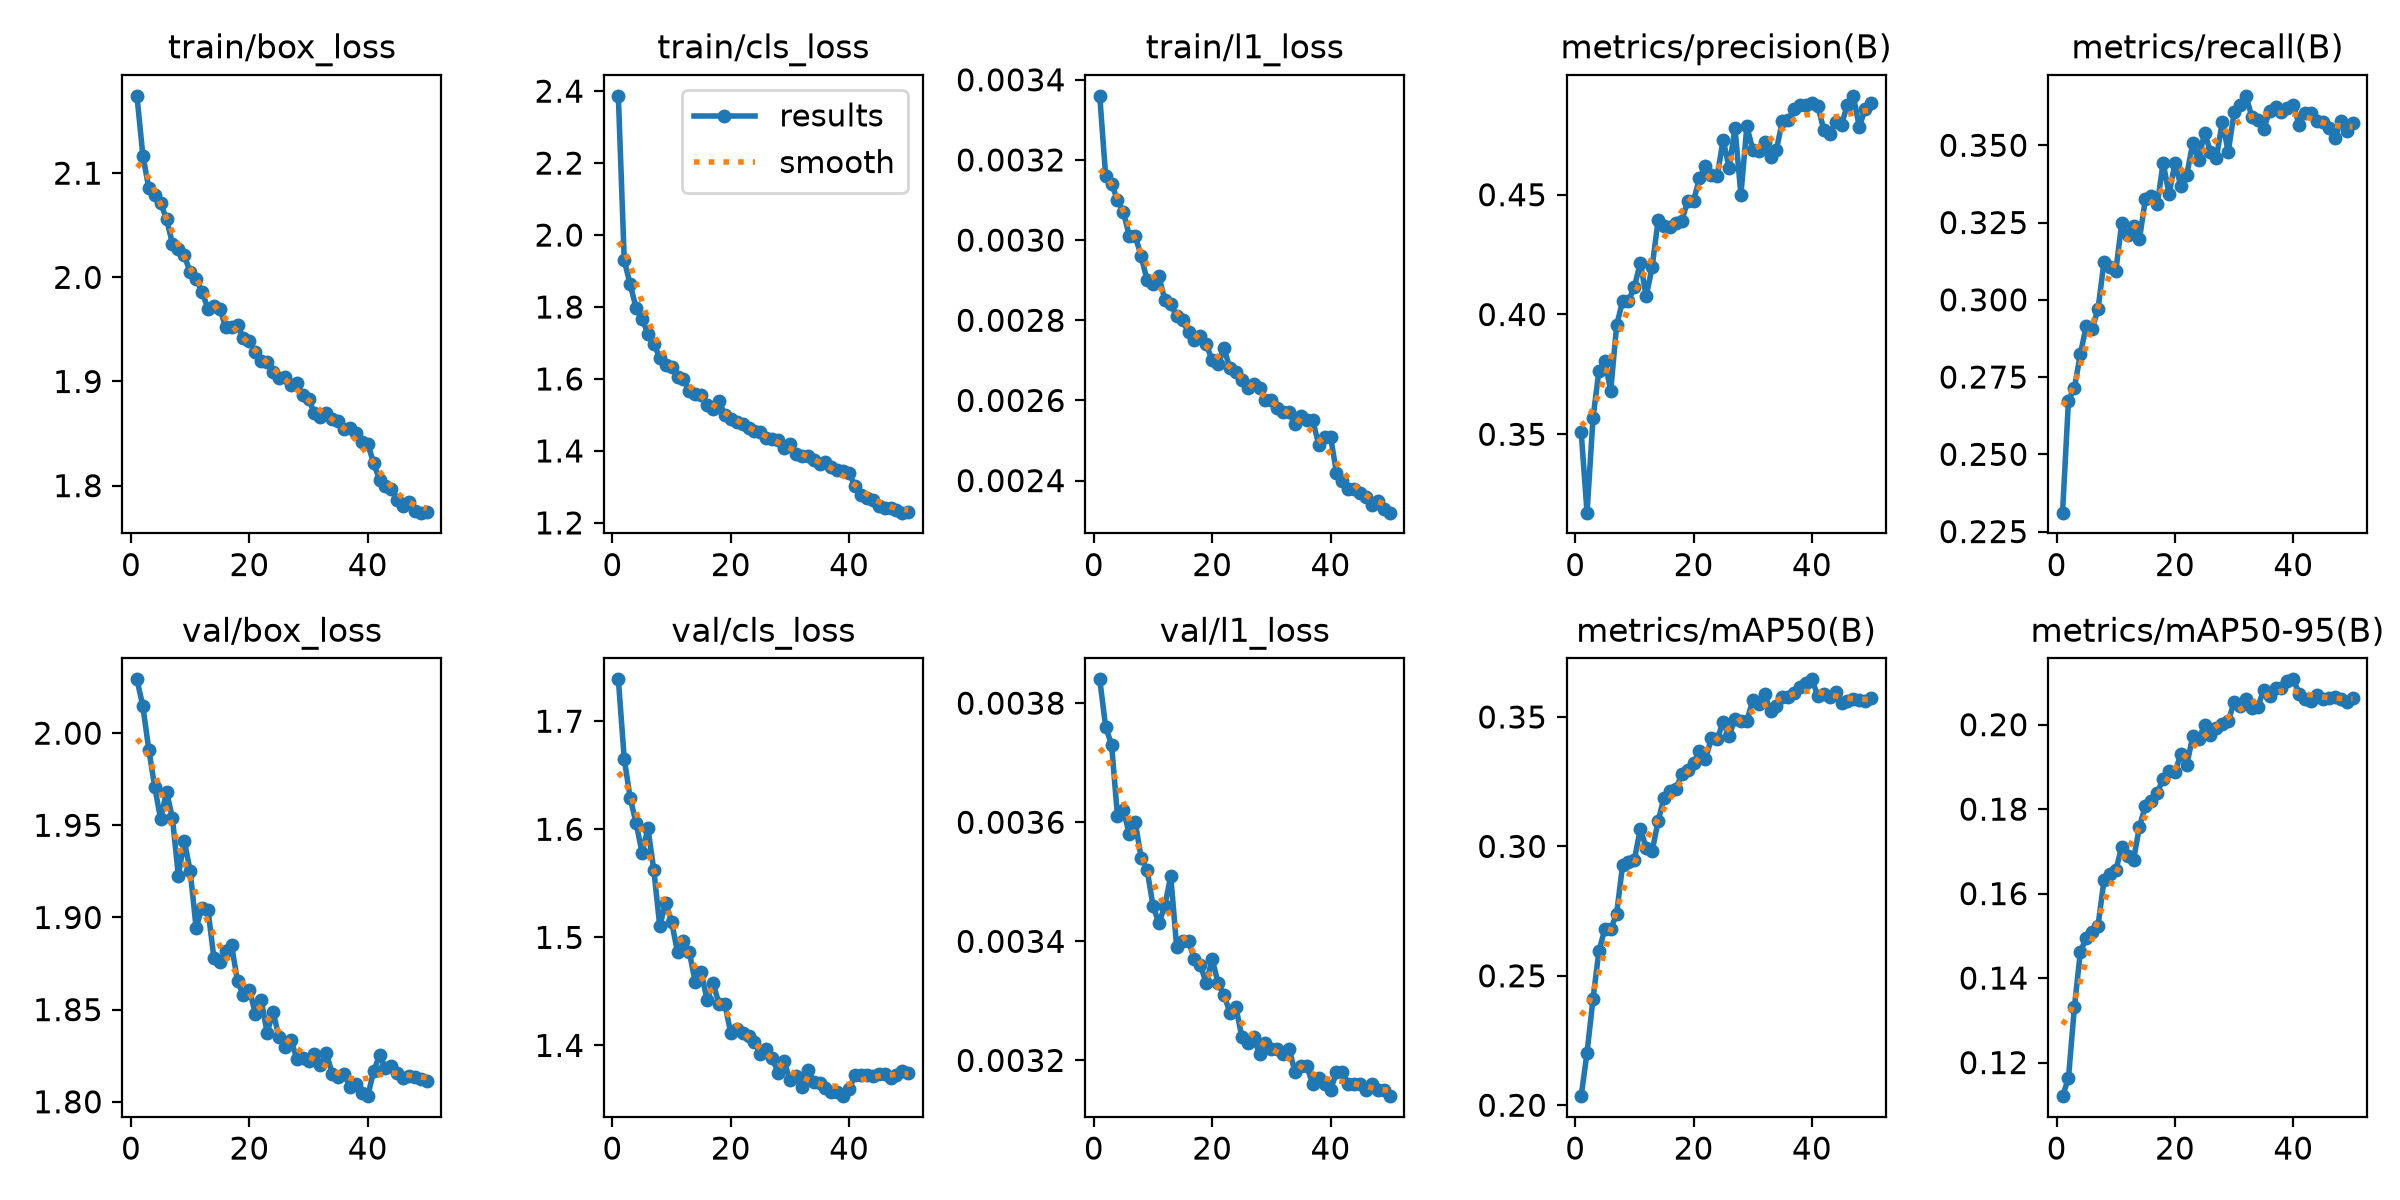

Training output folder: C:\Users\anyan\source\repos\AeroTrack\runs\visdrone_yolo26s


In [9]:
results_plot = TRAIN_RUN_DIR / "results.png"

if results_plot.exists():
    display(IPyImage(filename=str(results_plot)))
else:
    print("Training results plot was not found:", results_plot)

print("Training output folder:", TRAIN_RUN_DIR)

#### If training runs out of GPU memory

Your laptop GPU has limited VRAM. If YOLO26s at batch 1 and image size 640 still runs out of memory:

1. Restart the Jupyter kernel to release allocated GPU memory.
2. Change `BASE_MODEL` to `yolo26n.pt`.
3. Use `imgsz=512` and `batch=1`.
4. Give the run a new name, such as `visdrone_yolo26n_fallback`.
5. Repeat the smoke test before the full training run.

Do not silently change the model or image size in the middle of an experiment. Record the configuration so we can compare results fairly.

In [ ]:
# run only if YOLO26s training runs out of memory.

# FALLBACK_MODEL = "yolo26n.pt"

# fallback_model = YOLO(FALLBACK_MODEL)

# fallback_results = fallback_model.train(
#     data="VisDrone.yaml",
#     epochs=50,
#     imgsz=512,
#     batch=1,
#     workers=0,
#     device=DEVICE,
#     patience=15,
#     amp=True,
#     cache=False,
#     save=True,
#     plots=True,
#     close_mosaic=10,
#     project=str(RUNS_DIR),
#     name="visdrone_yolo26n_fallback",
#     exist_ok=True,
#     verbose=True
# )

Fine-tuned classes:
{0: 'pedestrian', 1: 'people', 2: 'bicycle', 3: 'car', 4: 'van', 5: 'truck', 6: 'tricycle', 7: 'awning-tricycle', 8: 'bus', 9: 'motor'}
Original detections: 7
Fine-tuned detections: 6


,class_id,class_name,detections
0,0,pedestrian,6
1,1,people,0


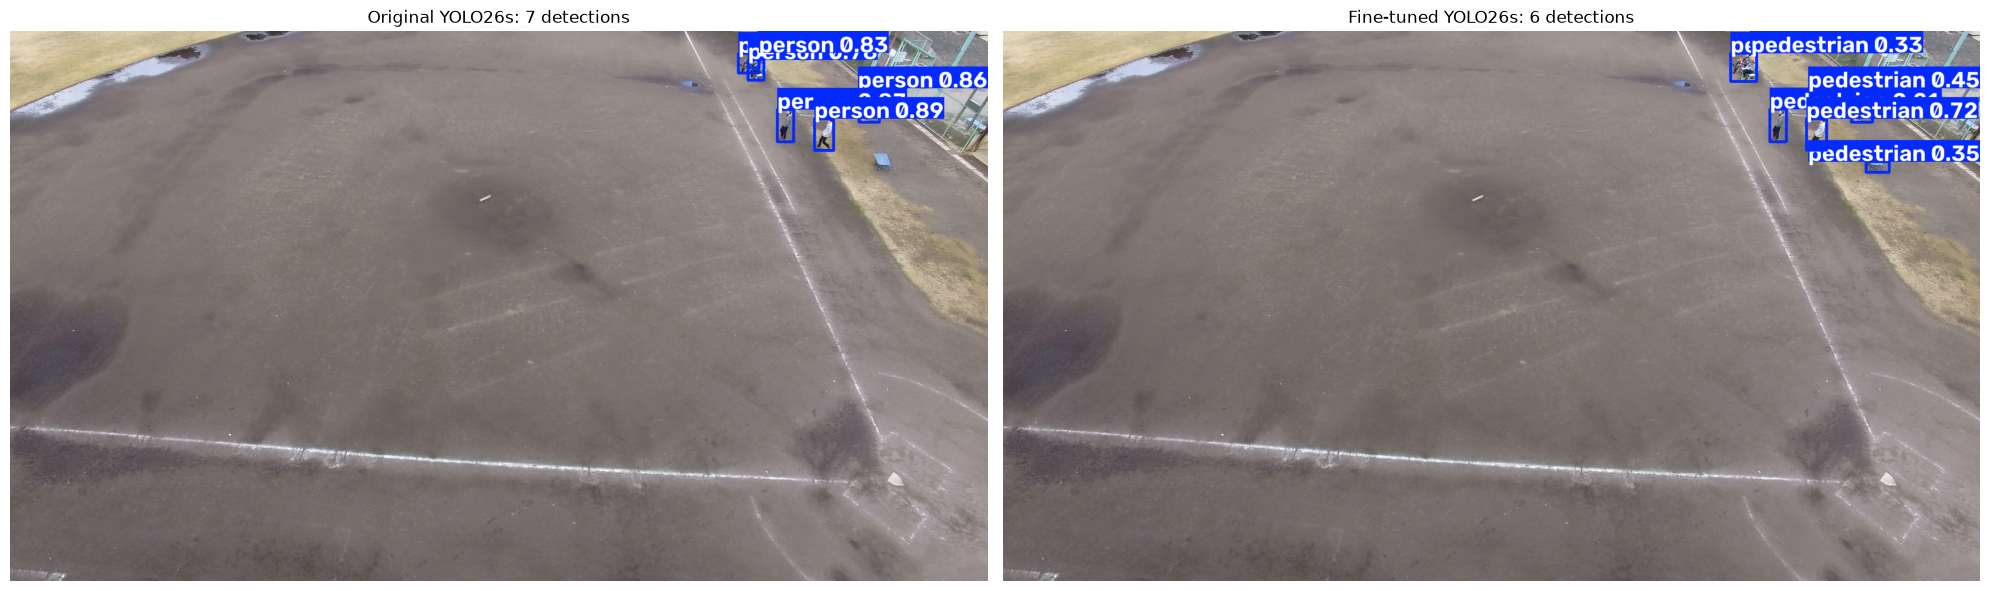

Comparison saved: c:\Users\anyan\source\repos\AeroTrack\outputs\visdrone_finetuning_comparison.jpg


In [10]:

from ultralytics import YOLO
from pathlib import Path
from collections import Counter
import cv2
import matplotlib.pyplot as plt
import pandas as pd

# Locate the best fine-tuned checkpoint.
BEST_MODEL_PATH = (
    PROJECT_DIR / "runs" / "visdrone_yolo26s" /
    "weights" / "best.pt"
)

if not BEST_MODEL_PATH.exists():
    raise FileNotFoundError(BEST_MODEL_PATH)

# Load original and fine-tuned models.
original_model = YOLO("yolo26s.pt")
finetuned_model = YOLO(str(BEST_MODEL_PATH))

# VisDrone classes used for person detection.
PERSON_CLASSES = [0, 1]

print("Fine-tuned classes:")
print(finetuned_model.names)

# Select the same frame we previously inspected.
TEST_SECONDS = 65

cap = cv2.VideoCapture(str(VIDEO_PATH))
cap.set(cv2.CAP_PROP_POS_MSEC, TEST_SECONDS * 1000)

success, test_frame = cap.read()
cap.release()

if not success:
    raise ValueError("Could not read the selected video frame.")

# Identical detection settings for both models.
settings = {
    "source": test_frame,
    "imgsz": 640,
    "conf": 0.15,
    "max_det": 300,
    "tile": 640,
    "tile_overlap": 0.20,
    "device": DEVICE,
    "verbose": False
}

# Original COCO model: person class 0.
original_result = original_model.predict(
    classes=[0],
    **settings
)[0]

# Fine-tuned VisDrone model: pedestrian and people.
finetuned_result = finetuned_model.predict(
    classes=PERSON_CLASSES,
    **settings
)[0]

# Count detections.
original_count = len(original_result.boxes)
finetuned_count = len(finetuned_result.boxes)

print("Original detections:", original_count)
print("Fine-tuned detections:", finetuned_count)

# Show how the fine-tuned model distributes detections
# between its two person-related categories.
class_counts = Counter(
    finetuned_result.boxes.cls.int().cpu().tolist()
)

class_summary = pd.DataFrame([
    {
        "class_id": class_id,
        "class_name": finetuned_model.names[class_id],
        "detections": class_counts.get(class_id, 0)
    }
    for class_id in PERSON_CLASSES
])

display(class_summary)

# Visual comparison.
fig, axes = plt.subplots(1, 2, figsize=(20, 9))

axes[0].imshow(
    cv2.cvtColor(original_result.plot(), cv2.COLOR_BGR2RGB)
)
axes[0].set_title(
    f"Original YOLO26s: {original_count} detections"
)
axes[0].axis("off")

axes[1].imshow(
    cv2.cvtColor(finetuned_result.plot(), cv2.COLOR_BGR2RGB)
)
axes[1].set_title(
    f"Fine-tuned YOLO26s: {finetuned_count} detections"
)
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Save the comparison.
comparison_path = OUTPUT_DIR / "visdrone_finetuning_comparison.jpg"

fig.savefig(
    comparison_path,
    bbox_inches="tight",
    dpi=150
)

print("Comparison saved:", comparison_path)


In [11]:

import cv2
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

# Select different moments from the drone video.
TEST_TIMESTAMPS = [5, 15, 25, 35, 45, 55, 65, 72]

# Create a folder for the comparison images.
COMPARISON_DIR = OUTPUT_DIR / "multi_frame_comparison"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

results = []

for seconds in TEST_TIMESTAMPS:

    cap = cv2.VideoCapture(str(VIDEO_PATH))
    cap.set(cv2.CAP_PROP_POS_MSEC, seconds * 1000)

    success, frame = cap.read()
    cap.release()

    if not success:
        print(f"Could not read frame at {seconds}s")
        continue

    # Same settings for both models.
    settings = {
        "source": frame,
        "imgsz": 640,
        "conf": 0.15,
        "max_det": 300,
        "tile": 640,
        "tile_overlap": 0.20,
        "device": DEVICE,
        "verbose": False
    }

    # Original model detects COCO person class.
    original_result = original_model.predict(
        classes=[0],
        **settings
    )[0]

    # Fine-tuned model detects both VisDrone person classes.
    fine_result = finetuned_model.predict(
        classes=[0, 1],
        **settings
    )[0]

    original_count = len(original_result.boxes)
    fine_count = len(fine_result.boxes)

    # Save counts for each timestamp.
    results.append({
        "timestamp_seconds": seconds,
        "actual_visible_people": "",
        "original_detections": original_count,
        "finetuned_detections": fine_count,
        "difference": fine_count - original_count
    })

    # Draw bounding boxes.
    original_image = original_result.plot()
    fine_image = fine_result.plot()

    # Resize both images for easier comparison.
    target_width = 1280
    target_height = int(
        target_width * frame.shape[0] / frame.shape[1]
    )

    original_image = cv2.resize(
        original_image, (target_width, target_height)
    )

    fine_image = cv2.resize(
        fine_image, (target_width, target_height)
    )

    # Place results side by side.
    combined = np.hstack([original_image, fine_image])

    # Save the comparison image.
    output_file = COMPARISON_DIR / f"comparison_{seconds}s.jpg"
    cv2.imwrite(str(output_file), combined)

    print(
        f"{seconds}s | Original: {original_count} | "
        f"Fine-tuned: {fine_count}"
    )

# Export the comparison table.
comparison_df = pd.DataFrame(results)

CSV_PATH = COMPARISON_DIR / "comparison_results.csv"
comparison_df.to_csv(CSV_PATH, index=False)

display(comparison_df)

print("Comparison images:", COMPARISON_DIR)
print("Results CSV:", CSV_PATH)


5s | Original: 7 | Fine-tuned: 6
15s | Original: 9 | Fine-tuned: 11
25s | Original: 9 | Fine-tuned: 13
35s | Original: 8 | Fine-tuned: 12
45s | Original: 1 | Fine-tuned: 12
55s | Original: 7 | Fine-tuned: 4
65s | Original: 7 | Fine-tuned: 6
72s | Original: 10 | Fine-tuned: 12


,timestamp_seconds,actual_visible_people,original_detections,finetuned_detections,difference
0,5,,7,6,-1
1,15,,9,11,2
2,25,,9,13,4
3,35,,8,12,4
4,45,,1,12,11
5,55,,7,4,-3
6,65,,7,6,-1
7,72,,10,12,2


Comparison images: c:\Users\anyan\source\repos\AeroTrack\outputs\multi_frame_comparison
Results CSV: c:\Users\anyan\source\repos\AeroTrack\outputs\multi_frame_comparison\comparison_results.csv
